<a href="https://colab.research.google.com/github/YomnaAhmed97/Olist-Ecommerce-Analysis/blob/main/Brazilian_E_Commerce_Public_Dataset_by_Olist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [169]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [170]:
import pandas as pd
import os
#List files in the download directory
print("Files in the download directory:")
for file in os.listdir(path):
    print(file)

Files in the download directory:
olist_customers_dataset.csv
olist_sellers_dataset.csv
olist_order_reviews_dataset.csv
olist_order_items_dataset.csv
olist_products_dataset.csv
olist_geolocation_dataset.csv
product_category_name_translation.csv
olist_orders_dataset.csv
olist_order_payments_dataset.csv


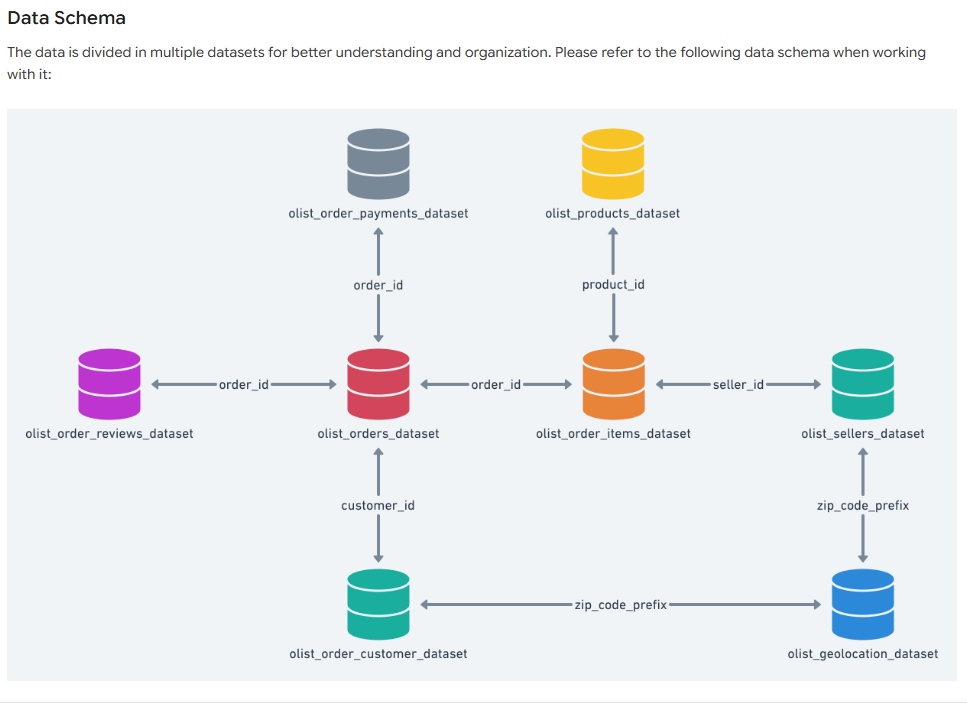

In [171]:
orders=pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"))
items = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))
products = pd.read_csv(os.path.join(path, "olist_products_dataset.csv"))
payments = pd.read_csv(os.path.join(path, "olist_order_payments_dataset.csv"))
for name, df in zip(["orders", "items", "products", "payments"], [orders, items, products, payments]):
    print(name, df.shape)

orders (99441, 8)
items (112650, 7)
products (32951, 9)
payments (103886, 5)


In [172]:
for name, df in zip(["orders", "items", "products", "payments"], [orders, items, products, payments]):
  print(name)
  print(df.columns.to_list())
  print("\n")

orders
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


items
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


products
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


payments
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']




In [173]:
items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [174]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


خلي بالك :
عدد الطلبات: 99,441، ودي نفس الرقم اللي في الأعمدة الأولى (order_id وcustomer_id وorder_status وتاريخ الشراء) من غير أي نقص
------------------------------------
====================================

القيم الناقصة:

 order_approved_at ناقص فيه حوالي 160 صف

  وorder_delivered_carrier_date ناقص حوالي 1,783
  
وorder_delivered_customer_date ناقص حوالي 2,965


--------------------------------------



In [175]:
orders["order_status"].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [176]:
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
print(orders["order_purchase_timestamp"].min())
print(orders["order_purchase_timestamp"].max())

2016-09-04 21:15:19
2018-10-17 17:30:18


In [177]:
delivered = orders[orders["order_status"] == "delivered"]
sales = (items.merge(delivered[["order_id", "order_purchase_timestamp"]], on="order_id").merge(products[["product_id", "product_category_name"]], on="product_id", how="left"))
print(sales.shape)
sales.head()


(110197, 9)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,ferramentas_jardim


In [178]:
sales['product_category_name'].isna().sum()

np.int64(1537)

In [179]:
"""

الـ 1,537 قطعة من غير فئة هنسميها unknown بدل ما نشيلها، عشان إجمالي الإيراد يفضل كامل. وأسماء الفئات بالبرتغالي، فهنجيب ترجمتها من الملف اللي حمّلناه.
"""

translation = pd.read_csv(os.path.join(path, "product_category_name_translation.csv"))
translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [180]:
sales["product_category_name"]=sales['product_category_name'].fillna("unknown")
sales= sales.merge(translation, on = "product_category_name", how = "left")
sales["category"]=sales["product_category_name"].fillna(sales["product_category_name"])
print(sales.shape)

(110197, 11)


In [181]:
# طلعت 110197 وده كده معناه انه مظبوط مع عدد delivered

In [182]:
print(translation.head(3))
mapping = dict(zip(translation.iloc[:, 0], translation.iloc[:, 1]))
sales["category"] = sales["product_category_name"].map(mapping).fillna(sales["product_category_name"])
print((sales["category"] == sales["product_category_name"]).mean())

    product_category_name product_category_name_english
0            beleza_saude                 health_beauty
1  informatica_acessorios         computers_accessories
2              automotivo                          auto
0.08196230387397116


# **Data Analyst**

1) Which product categories sell the most by units, and which earn the most revenue?

**Top categories sell the most units**

In [187]:
by_category = (
    sales.groupby("category")
    .agg(
        units=("order_item_id", "count"),
        revenue=("price", "sum"),
        products=("product_id", "nunique"),
        orders=("order_id", "nunique"),
    )
)
by_category.sort_values("units", ascending=False).head(10)

,units,revenue,products,orders
category,,,,
bed_bath_table,10953,1023434.76,2991,9272
health_beauty,9465,1233131.72,2397,8647
sports_leisure,8431,954852.55,2822,7530
furniture_decor,8160,711927.69,2593,6307
computers_accessories,7644,888724.61,1600,6530
housewares,6795,615628.69,2282,5743
watches_gifts,5859,1166176.98,1300,5495
telephony,4430,309860.23,1112,4093
garden_tools,4268,470495.28,725,3448




```
# Top 3 Categories
```


1. Bed Bath Table

2. Health Beauty

3. Sports Leisure



---



**Top categories sell the most revenue**

In [188]:
by_category.sort_values("revenue", ascending=False).head(10)

,units,revenue,products,orders
category,,,,
health_beauty,9465,1233131.72,2397,8647
watches_gifts,5859,1166176.98,1300,5495
bed_bath_table,10953,1023434.76,2991,9272
sports_leisure,8431,954852.55,2822,7530
computers_accessories,7644,888724.61,1600,6530
furniture_decor,8160,711927.69,2593,6307
housewares,6795,615628.69,2282,5743
cool_stuff,3718,610204.10,770,3559
auto,4140,578966.65,1853,3810




```
# Top 3 Categories
```


1. Health Beauty

2. Watches Gifts

3. Bed Bath Table







---



**Top categories the most orders**

In [189]:
by_category.sort_values("orders", ascending=False).head(10)

,units,revenue,products,orders
category,,,,
bed_bath_table,10953,1023434.76,2991,9272
health_beauty,9465,1233131.72,2397,8647
sports_leisure,8431,954852.55,2822,7530
computers_accessories,7644,888724.61,1600,6530
furniture_decor,8160,711927.69,2593,6307
housewares,6795,615628.69,2282,5743
watches_gifts,5859,1166176.98,1300,5495
telephony,4430,309860.23,1112,4093
auto,4140,578966.65,1853,3810


In [185]:
sales.loc[sales["category"] == sales["product_category_name"], "category"].value_counts()

,count
category,
cool_stuff,3718
pet_shop,1924
unknown,1537
consoles_games,1089
audio,362
market_place,305
dvds_blu_ray,61
portateis_cozinha_e_preparadores_de_alimentos,14
la_cuisine,14




```
# Top 3 Categories
```


1. Bed Bath Table

2. Health Beauty

3. Sports Leisure



---



**Calculate the Average**

In [184]:
by_category["avg_price"] = (by_category["revenue"] / by_category["units"]).round(1)
by_category["units_per_product"] = (by_category["units"] / by_category["products"]).round(1)
by_category["revenue_per_order"] = (by_category["revenue"] / by_category["orders"]).round(1)
by_category.sort_values("revenue", ascending=False).head(10)

,units,revenue,products,orders,avg_price,units_per_product,revenue_per_order
category,,,,,,,
health_beauty,9465,1233131.72,2397,8647,130.3,3.9,142.6
watches_gifts,5859,1166176.98,1300,5495,199.0,4.5,212.2
bed_bath_table,10953,1023434.76,2991,9272,93.4,3.7,110.4
sports_leisure,8431,954852.55,2822,7530,113.3,3.0,126.8
computers_accessories,7644,888724.61,1600,6530,116.3,4.8,136.1
furniture_decor,8160,711927.69,2593,6307,87.2,3.1,112.9
housewares,6795,615628.69,2282,5743,90.6,3.0,107.2
cool_stuff,3718,610204.10,770,3559,164.1,4.8,171.5
auto,4140,578966.65,1853,3810,139.8,2.2,152.0
